# SECT-4451 Lecture 2 Practical: Data Exploration and Foundational Math

**Name:** Mekdelawit Alemayehu 
**ID:** UGR/9271/16



In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

n = 100
study_hours = np.random.normal(5, 2, n)
attendance = np.random.normal(85, 10, n)
previous_mark = np.random.normal(70, 15, n)
final_score = (0.5 * study_hours) + (0.3 * attendance) + (0.2 * previous_mark) + np.random.normal(0, 5, n)

df = pd.DataFrame({
    'study_hours': study_hours,
    'attendance': attendance,
    'previous_mark': previous_mark,
    'final_score': final_score
})

df.loc[0:5, 'study_hours'] = np.nan   # Missing values
df.loc[99, 'study_hours'] = 50        # Outlier
df.loc[98, 'attendance'] = -10        # Impossible value

df.head(10)

,study_hours,attendance,previous_mark,final_score
0,NaN,70.846293,75.366810,35.178989
1,NaN,80.793547,78.411768,39.481248
2,NaN,81.572855,86.245769,48.605167
3,NaN,76.977227,85.807031,47.329456
4,NaN,83.387143,49.334959,37.044473
5,NaN,89.040509,55.932624,40.751177
6,8.158426,103.861859,77.725529,57.171201
7,6.534869,86.745778,77.706789,41.874669
8,4.061051,87.575504,77.725715,46.583807
9,6.085120,84.255541,127.790972,52.866454


## Part A: Inspect and Clean

Before changing anything, I looked at the summary statistics and counted the missing values to see what was wrong with the data.

In [2]:
print(df.describe().round(2))
print()
print("Missing values per column:")
print(df.isna().sum())

       study_hours  attendance  previous_mark  final_score
count        94.00      100.00         100.00       100.00
mean          5.22       84.27          70.97        42.69
std           5.01       13.48          16.26         6.09
min          -0.24      -10.00          21.38        29.16
25%           3.73       76.83          60.17        38.19
50%           4.81       85.84          71.47        42.76
75%           5.74       90.38          80.57        46.69
max          50.00      112.20         127.79        57.17

Missing values per column:
study_hours      6
attendance       0
previous_mark    0
final_score      0
dtype: int64


In [3]:
# The suspicious rows
df.loc[98:99]

,study_hours,attendance,previous_mark,final_score
98,5.010227,-10.000000,82.192932,44.045627
99,50.000000,73.570297,79.444433,46.414470


In [4]:
# How extreme is the 50-hour value compared with the other students?
others = df['study_hours'].drop(index=99).dropna()
z = (50 - others.mean()) / others.std()
print(f"Other students: mean = {others.mean():.2f} h, std = {others.std():.2f} h, max = {others.max():.2f} h")
print(f"50 hours is {z:.1f} standard deviations above the mean and {50 / others.max():.1f}x the next-highest value")

# Other values outside a valid range
print()
print("Negative study_hours:", (df['study_hours'] < 0).sum())
print("Attendance below 0 or above 100:", ((df['attendance'] < 0) | (df['attendance'] > 100)).sum())
print("Previous mark above 100:", (df['previous_mark'] > 100).sum())

Other students: mean = 4.74 h, std = 1.84 h, max = 8.70 h
50 hours is 24.6 standard deviations above the mean and 5.7x the next-highest value

Negative study_hours: 1
Attendance below 0 or above 100: 8
Previous mark above 100: 5


### A1. The study_hours outlier

I decided to **remove** the student with 50 study hours (row 99).

My reasons:

1. The value doesn't make sense next to the rest of the data. The other students study 4.74 hours on average, with a standard deviation of 1.84 hours, and the highest is 8.70 hours. 50 hours is 24.6 standard deviations above the average and almost 6 times the next highest value. Something that extreme doesn't happen by chance, so it's most likely a typing mistake, like 5.0 entered as 50.
2. I chose removing over capping because capping means replacing it with a number I made up, such as 8.7 hours. I don't actually know how much this student studied, so any replacement would be a guess. It's only 1 row out of 100, so dropping it costs very little.

While inspecting, I also found other problems and fixed them:

- **Attendance of -10 (row 98).** Attendance can't be negative. The rest of this student's data looks normal, so I kept the row and replaced only that value with the median attendance (86.27).
- **6 missing study_hours values (rows 0 to 5).** I filled these with the median (4.77 hours). I used the median instead of the mean because extreme values don't affect it as much. Deleting these rows would have thrown away good attendance, mark and score data for 6 students.
- **Values outside a possible range.** Because the data was randomly generated, 13 rows have values that can't happen in real life: one negative study time (-0.24 hours), 7 attendance values over 100%, and 5 previous marks over 100. Assuming attendance is a percentage and marks are out of 100, I clipped these to the nearest valid value (0 hours, 100%, 100 marks). Deleting them would have cost 13% of the data.

In [5]:
clean = df.drop(index=99).copy()                      # remove outlier

clean.loc[clean['attendance'] < 0, 'attendance'] = np.nan
clean = clean.fillna(clean.median())                  # fill missing with median

# Clip remaining impossible values to valid ranges
clean['study_hours'] = clean['study_hours'].clip(lower=0)
clean['attendance'] = clean['attendance'].clip(0, 100)
clean['previous_mark'] = clean['previous_mark'].clip(0, 100)

print("Missing values left:", clean.isna().sum().sum())
clean.describe().round(2)

Missing values left: 0


,study_hours,attendance,previous_mark,final_score
count,99.00,99.00,99.00,99.00
mean,4.74,84.94,70.50,42.65
std,1.78,8.64,15.34,6.11
min,0.00,65.81,21.38,29.16
25%,3.80,77.07,60.14,38.13
50%,4.77,86.27,71.23,42.67
75%,5.72,90.54,80.84,46.78
max,8.70,100.00,100.00,57.17


### A2. Shape, numerical columns and target

In [6]:
X = clean.drop(columns='final_score')   # feature matrix
y = clean['final_score']                 # target

print("Feature matrix shape:", X.shape)
print("Numerical columns:", clean.select_dtypes(include='number').columns.tolist())
print("Target variable: final_score")

Feature matrix shape: (99, 3)
Numerical columns: ['study_hours', 'attendance', 'previous_mark', 'final_score']
Target variable: final_score


- The feature matrix has shape **(99, 3)**. That's 99 students (after removing the outlier) and 3 features.
- **All four columns are numerical**.
- The **target variable** is `final_score`, because that's what we want to predict. The features are `study_hours`, `attendance` and `previous_mark`.

## Part B: Summarize

### B1. Mean, median and standard deviation

In [7]:
summary = pd.DataFrame({
    'mean': clean.mean(),
    'median': clean.median(),
    'std': clean.std()
}).round(2)
summary

,mean,median,std
study_hours,4.74,4.77,1.78
attendance,84.94,86.27,8.64
previous_mark,70.50,71.23,15.34
final_score,42.65,42.67,6.11


### B2. Observations

1. Final scores are balanced around 42.7. The mean (42.65) and median (42.67) are almost the same, which means there isn't a group of very high or very low scores pulling the average one way. The standard deviation is 6.11, so most students scored within about 6 points of 42.7.
2. Previous marks vary the most. Their standard deviation is 15.34 marks, so students came into the course with very different backgrounds. Attendance is much more consistent (standard deviation 8.64). Its median (86.27) is a bit higher than its mean (84.94), which tells me a few students with low attendance are dragging the average down.
3. Study hours are close together. The standard deviation is only 1.78 hours around an average of 4.74, so most students study somewhere between 3 and 6.5 hours. I also noticed the columns use very different scales: study hours are single digits, while attendance and marks are mostly between 60 and 100. That becomes important in Part F.

## Part C: Visualize

### C1. Histogram of final_score

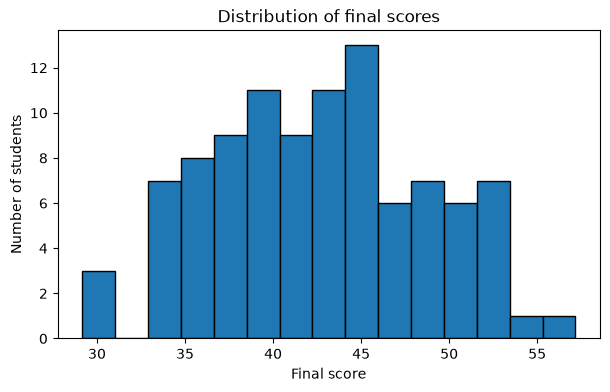

In [8]:
plt.figure(figsize=(7, 4))
plt.hist(clean['final_score'], bins=15, edgecolor='black')
plt.xlabel('Final score')
plt.ylabel('Number of students')
plt.title('Distribution of final scores')
plt.show()

The histogram has a rough bell shape. About two thirds of the students scored between 36 and 49, the tallest bars are around 38 to 46, and only 4 students scored below 32 or above 54. This fits with what I saw in Part B, where the mean and median were almost equal.

### C2. Scatter plot of study_hours vs final_score

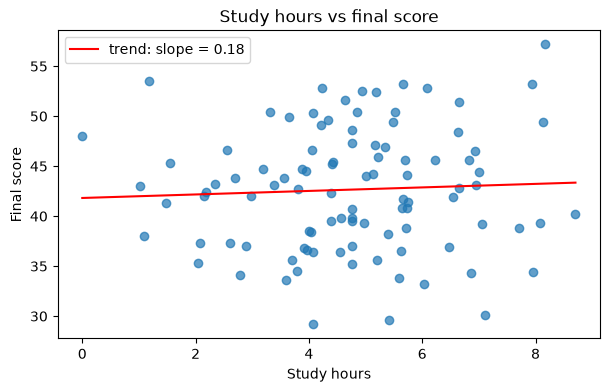

In [9]:
plt.figure(figsize=(7, 4))
plt.scatter(clean['study_hours'], clean['final_score'], alpha=0.7)

# Add a best-fit line to make the trend visible
m, c = np.polyfit(clean['study_hours'], clean['final_score'], 1)
xs = np.linspace(clean['study_hours'].min(), clean['study_hours'].max(), 100)
plt.plot(xs, m * xs + c, color='red', label=f'trend: slope = {m:.2f}')

plt.xlabel('Study hours')
plt.ylabel('Final score')
plt.title('Study hours vs final score')
plt.legend()
plt.show()

**Trend:** The points are spread out in a wide cloud and the trend line is almost flat. There is a very weak positive trend, so students who study more score slightly higher on average, but the effect is small and there's a lot of variation around it.

This makes sense if you look at how the data was created. Study hours only add 0.5 times the hours to the final score, which is a difference of about 1 point between a typical student and one who studies 2 hours more. The random noise added to every score has a standard deviation of 5 points, and attendance and previous mark add a lot more. So the effect of study hours gets lost.

## Part D: Correlation and Causality

### D1. Pearson correlation

In [10]:
from scipy import stats   # installed together with scikit-learn

r = clean['study_hours'].corr(clean['final_score'])   # Pearson by default
print(f"Pearson r (study_hours, final_score) = {r:.3f}")

r_check, p_value = stats.pearsonr(clean['study_hours'], clean['final_score'])
print(f"p-value = {p_value:.2f}")

# For comparison, all pairwise correlations:
clean.corr().round(3)

Pearson r (study_hours, final_score) = 0.051
p-value = 0.61


,study_hours,attendance,previous_mark,final_score
study_hours,1.000,-0.083,0.157,0.051
attendance,-0.083,1.000,-0.043,0.429
previous_mark,0.157,-0.043,1.000,0.539
final_score,0.051,0.429,0.539,1.000


The Pearson correlation is **r = 0.051**. That's a very weak positive correlation, close to no relationship at all. The p-value is 0.61, which means a correlation this small could easily happen by chance, so it isn't statistically significant. For comparison, previous_mark (r = 0.54) and attendance (r = 0.43) are much more strongly related to the final score.

### D2. Critical thinking

**Does studying 10 hours guarantee a specific score?** No, for a few reasons:

- A correlation describes a general pattern across a group of students. It doesn't tell you exactly what one person will get. Even with a strong correlation, students who study the same amount still end up with different scores. Here the correlation is almost zero, so study hours alone tell us very little about a student's score.
- Nobody in the data studied 10 hours (the maximum is 8.70), so predicting a score at 10 hours means guessing outside the range we have data for.
- Correlation doesn't prove that one thing causes the other.

**A possible lurking variable: motivation.** A motivated student is likely to study more and also likely to do better in other ways, like paying attention in class, doing practice questions and asking for help. That would make study time and scores move together even if the extra hours weren't the main reason for the higher score. Other possible confounders are prior knowledge of the subject, how much sleep students get, and whether they have a quiet place to study.

## Part E: Vectors and Dot Product

### E1 to E3

In [11]:
# E1: pick one student (row 10, its values are original, not filled in)
x = X.iloc[10].values
print("x (study_hours, attendance, previous_mark) =", x.round(2))

# E2: weights and bias
w = np.array([0.5, 0.2, 0.4])
b = 5

# E3: y = w · x + b
y_hat = np.dot(w, x) + b
print(f"Predicted score y = w.x + b = {y_hat:.2f}")
print(f"Actual final_score            = {y.iloc[10]:.2f}")

# Step by step
print("\nStep by step:")
for name, wi, xi in zip(X.columns, w, x):
    print(f"  {wi} x {xi:.2f} ({name}) = {wi*xi:.2f}")
print(f"  + bias {b}")

x (study_hours, attendance, previous_mark) = [ 4.07 65.81 78.56]
Predicted score y = w.x + b = 51.62
Actual final_score            = 36.40

Step by step:
  0.5 x 4.07 (study_hours) = 2.04
  0.2 x 65.81 (attendance) = 13.16
  0.4 x 78.56 (previous_mark) = 31.43
  + bias 5


### E4. Conceptual questions

**What does w represent?** Each number in w is a weight that says how much one feature affects the predicted score. It tells you how much the prediction goes up when that feature increases by 1, if the other features stay the same. With w = [0.5, 0.2, 0.4], every extra study hour adds 0.5 points, every extra attendance point adds 0.2, and every extra previous mark point adds 0.4. A bigger weight means the feature matters more, and a negative weight would mean the feature lowers the score.

**Why do we need b?** The bias is the starting value of the prediction, which is what the model predicts when all the features are 0. Without it, the model would have to predict 0 whenever all the inputs are 0, so the prediction line would always pass through the origin. That usually doesn't fit real data. The bias moves the whole prediction up or down so it can match the actual level of the scores. It works the same way as c in y = mx + c.

Note: these weights were given to us, not learned from the data, which is why the prediction (51.62) is quite far from this student's actual score (36.40). Later, a model like linear regression will learn the best w and b from the data.

## Part F: Scaling

### F1. Standardizing study_hours and previous_mark

In [12]:
scaled = clean.copy()
for col in ['study_hours', 'previous_mark']:
    scaled[col + '_z'] = (clean[col] - clean[col].mean()) / clean[col].std()

print(scaled[['study_hours', 'study_hours_z', 'previous_mark', 'previous_mark_z']].head().round(2))
print()
print("After scaling (mean should be 0, std should be 1):")
print(scaled[['study_hours_z', 'previous_mark_z']].agg(['mean', 'std']).round(3))

   study_hours  study_hours_z  previous_mark  previous_mark_z
0         4.77           0.02          75.37             0.32
1         4.77           0.02          78.41             0.52
2         4.77           0.02          86.25             1.03
3         4.77           0.02          85.81             1.00
4         4.77           0.02          49.33            -1.38

After scaling (mean should be 0, std should be 1):
      study_hours_z  previous_mark_z
mean           -0.0              0.0
std             1.0              1.0


In [13]:
# Compare the original ranges
for col in ['study_hours', 'previous_mark']:
    lo, hi = clean[col].min(), clean[col].max()
    print(f"{col:14s} range: {lo:6.2f} to {hi:6.2f}  (spread about {hi - lo:.1f})")

study_hours    range:   0.00 to   8.70  (spread about 8.7)
previous_mark  range:  21.38 to 100.00  (spread about 78.6)


### F2. Why KNN would fail without scaling

KNN decides which students are most similar by measuring the distance between them, usually the Euclidean distance:

$$d = \sqrt{(\text{difference in study hours})^2 + (\text{difference in previous mark})^2}$$

The problem is the two features have very different ranges. Study hours go from 0 to 8.7 (a spread of about 9), while previous marks go from 21.4 to 100 (a spread of about 79).

So a normal difference of 2 study hours adds 2 squared = 4 to the distance, but a normal difference of 15 marks adds 15 squared = 225. The distance ends up depending almost entirely on previous_mark, and study_hours is basically ignored. KNN would be judging similarity based on which feature happens to use bigger numbers, not on which feature actually matters.

After standardizing, both features are measured in standard deviations from their mean. A difference of 1 means the same thing in both columns, so both features count equally in the distance.